# IMDb Movies Analysis
**Milestone 1 – CIE:** Data Transformation, Null Value Handling (Mean Imputation), Insights and Visualization using Python and Pandas

**Dataset:** IMDb movies CSV (4,916 movies, 28 columns) – director, actors, genres, budget, gross, IMDb score, country, content rating, release year, etc.

## 1. Dataset Selection and Reading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("imdb_movies.csv")
df.head()

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0


## 2. Data Understanding

In [2]:
print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
df.info()

Rows and columns: (4916, 28)
Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 4916 entries, 0 to 4915
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      4897 non-null   str    
 1   director_name              4814 non-null   str    
 2   num_critic_for_reviews     4867 non-null   float64
 3   duration                   4901 non-null   float64
 4   director_facebook_likes    4814 non-null   float64
 5   actor_3_facebook_likes     4893 non-null   float64
 6   actor_2_name               4903 non-null   str    
 7   actor_1_facebook_likes     4909 non-null   float64
 8   gross                      4054 non-null   float64
 9   genres                     4916 non-null   str    
 10  actor_1_name               4909 non-null   str    
 11  movie_title                4916 non-null   str    
 12  num_voted_users            4916 non-null   int64  
 13  cast_total_f

In [3]:
df.describe()

,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_1_facebook_likes,gross,num_voted_users,cast_total_facebook_likes,facenumber_in_poster,num_user_for_reviews,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
count,4867.000000,4901.000000,4814.000000,4893.000000,4909.000000,4.054000e+03,4.916000e+03,4916.000000,4903.000000,4895.000000,4.432000e+03,4810.000000,4903.000000,4916.000000,4590.000000,4916.000000
mean,137.988905,107.090798,691.014541,631.276313,6494.488491,4.764451e+07,8.264492e+04,9579.815907,1.377320,267.668846,3.654749e+07,2002.447609,1621.923516,6.437429,2.222349,7348.294142
std,120.239379,25.286015,2832.954125,1625.874802,15106.986884,6.737255e+07,1.383222e+05,18164.316990,2.023826,372.934839,1.002427e+08,12.453977,4011.299523,1.127802,1.402940,19206.016458
min,1.000000,7.000000,0.000000,0.000000,0.000000,1.620000e+02,5.000000e+00,0.000000,0.000000,1.000000,2.180000e+02,1916.000000,0.000000,1.600000,1.180000,0.000000
25%,49.000000,93.000000,7.000000,132.000000,607.000000,5.019656e+06,8.361750e+03,1394.750000,0.000000,64.000000,6.000000e+06,1999.000000,277.000000,5.800000,1.850000,0.000000
50%,108.000000,103.000000,48.000000,366.000000,982.000000,2.504396e+07,3.313250e+04,3049.000000,1.000000,153.000000,1.985000e+07,2005.000000,593.000000,6.600000,2.350000,159.000000
75%,191.000000,118.000000,189.750000,633.000000,11000.000000,6.110841e+07,9.377275e+04,13616.750000,2.000000,320.500000,4.300000e+07,2011.000000,912.000000,7.200000,2.350000,2000.000000
max,813.000000,511.000000,23000.000000,23000.000000,640000.000000,7.605058e+08,1.689764e+06,656730.000000,43.000000,5060.000000,4.200000e+09,2016.000000,137000.000000,9.500000,16.000000,349000.000000


In [4]:
df.columns

Index(['color', 'director_name', 'num_critic_for_reviews', 'duration',
       'director_facebook_likes', 'actor_3_facebook_likes', 'actor_2_name',
       'actor_1_facebook_likes', 'gross', 'genres', 'actor_1_name',
       'movie_title', 'num_voted_users', 'cast_total_facebook_likes',
       'actor_3_name', 'facenumber_in_poster', 'plot_keywords',
       'movie_imdb_link', 'num_user_for_reviews', 'language', 'country',
       'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes',
       'imdb_score', 'aspect_ratio', 'movie_facebook_likes'],
      dtype='str')

**Understanding:** each row is one movie. Numeric columns: `budget`, `gross`, `duration`, `imdb_score`, `num_voted_users`, `title_year` and Facebook-like counts. Text columns: `movie_title`, `director_name`, `genres` (several genres joined by `|`), `country`, `content_rating`, etc. Several columns have missing values, and `title_year` is stored as a decimal number.

## 3. Data Transformation

**3.1 Clean the movie title** (titles have a hidden extra space at the end)

In [5]:
print(repr(df["movie_title"][0]))
df["movie_title"] = df["movie_title"].str.strip()
print(repr(df["movie_title"][0]))

'Avatar'
'Avatar'


**3.2 Drop unnecessary columns**

In [6]:
print("Columns before:", df.shape[1])
df = df.drop(columns=["movie_imdb_link", "plot_keywords", "aspect_ratio", "facenumber_in_poster",
                      "actor_2_name", "actor_3_name", "actor_2_facebook_likes", "actor_3_facebook_likes"])
print("Columns after:", df.shape[1])

Columns before: 28
Columns after: 20


**3.3 Rename columns** to shorter names

In [7]:
df = df.rename(columns={"title_year": "release_year", "duration": "duration_min",
                        "num_voted_users": "votes", "actor_1_name": "lead_actor"})
df.columns

Index(['color', 'director_name', 'num_critic_for_reviews', 'duration_min',
       'director_facebook_likes', 'actor_1_facebook_likes', 'gross', 'genres',
       'lead_actor', 'movie_title', 'votes', 'cast_total_facebook_likes',
       'num_user_for_reviews', 'language', 'country', 'content_rating',
       'budget', 'release_year', 'imdb_score', 'movie_facebook_likes'],
      dtype='str')

**3.4 Add new columns** – the first genre of each movie and the number of genres

In [8]:
df["primary_genre"] = df["genres"].str.split("|").str[0]
df["num_genres"] = df["genres"].str.count("\\|") + 1
df[["movie_title", "genres", "primary_genre", "num_genres"]].head()

,movie_title,genres,primary_genre,num_genres
0,Avatar,Action|Adventure|Fantasy|Sci-Fi,Action,4
1,Pirates of the Caribbean: At World's End,Action|Adventure|Fantasy,Action,3
2,Spectre,Action|Adventure|Thriller,Action,3
3,The Dark Knight Rises,Action|Thriller,Action,2
4,Star Wars: Episode VII - The Force Awakens,Documentary,Documentary,1


**3.5 Group IMDb scores into categories** (new column `score_category`)

In [9]:
df["score_category"] = pd.cut(df["imdb_score"], bins=[0, 5, 6.5, 7.5, 10],
                              labels=["Poor", "Average", "Good", "Excellent"])
df["score_category"].value_counts()

score_category
Average      1915
Good         1758
Excellent     726
Poor          517
Name: count, dtype: int64

## 4. Handling Null Values

**4.1 Identify null values**

In [10]:
print("Total nulls:", df.isnull().sum().sum())
nulls = df.isnull().sum()
nulls[nulls > 0].sort_values(ascending=False)

Total nulls: 2093


gross                      862
budget                     484
content_rating             300
release_year               106
director_name              102
director_facebook_likes    102
num_critic_for_reviews      49
num_user_for_reviews        21
color                       19
duration_min                15
language                    14
actor_1_facebook_likes       7
lead_actor                   7
country                      5
dtype: int64

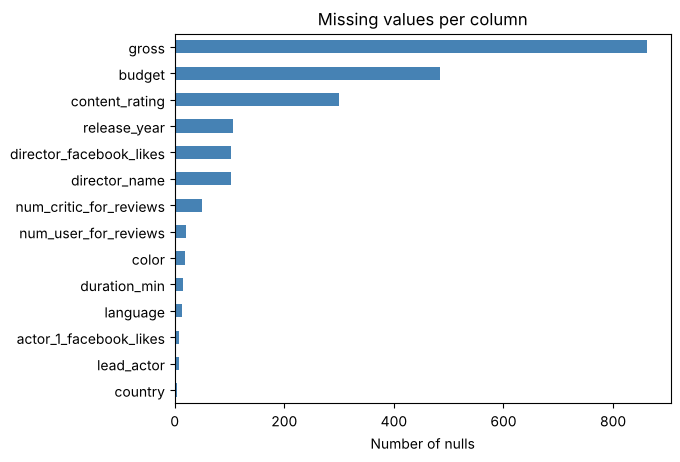

In [11]:
nulls[nulls > 0].sort_values().plot(kind="barh", color="steelblue")
plt.title("Missing values per column")
plt.xlabel("Number of nulls")
plt.show()

**4.2 Keep reliable rows for later insights.** Mean imputation fills in guessed values, so for revenue and year-based insights we first save the rows whose `gross`, `budget` and `release_year` were *real* (not missing). Money columns are compared only for USA movies, because other countries report budgets in their own currency.

In [12]:
# rows with a real release year (used for year / decade insights)
year_df = df[df["release_year"].notnull()].copy()

# USA movies with real gross and budget (used for money insights)
money_df = df[(df["country"] == "USA") & df["gross"].notnull() & df["budget"].notnull() & (df["budget"] >= 100000)].copy()
money_df["profit"] = money_df["gross"] - money_df["budget"]

print("Rows with real year:", len(year_df))
print("USA rows with real gross and budget:", len(money_df))

Rows with real year: 4810
USA rows with real gross and budget: 2968


**4.3 Mean imputation** – fill every numeric column that has nulls with the mean of that column

In [13]:
num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    if df[col].isnull().sum() > 0:
        mean_value = df[col].mean()
        print(col, "-> filled", df[col].isnull().sum(), "nulls with mean", round(mean_value, 2))
        df[col] = df[col].fillna(mean_value)

num_critic_for_reviews -> filled 49 nulls with mean 137.99
duration_min -> filled 15 nulls with mean 107.09
director_facebook_likes -> filled 102 nulls with mean 691.01
actor_1_facebook_likes -> filled 7 nulls with mean 6494.49
gross -> filled 862 nulls with mean 47644514.53
num_user_for_reviews -> filled 21 nulls with mean 267.67
budget -> filled 484 nulls with mean 36547486.03
release_year -> filled 106 nulls with mean 2002.45


**4.4 Text columns** have no mean, so their nulls are filled with `"Unknown"`

In [14]:
text_cols = ["color", "director_name", "lead_actor", "language", "country", "content_rating"]

for col in text_cols:
    df[col] = df[col].fillna("Unknown")

print("Remaining nulls:", df.isnull().sum().sum())

Remaining nulls: 0


**4.5 Change data types** – the year was decimal (mean-imputed values are rounded first)

In [15]:
df["release_year"] = df["release_year"].round().astype(int)
df["release_year"].dtype

dtype('int64')

**Observation:** the dataset had 2,093 null values in 14 columns. `gross` (862) and `budget` (484) have the most. The 8 numeric columns with nulls were filled with their mean (for example `gross` with about $47.6 million and `budget` with about $36.5 million), text columns were filled with "Unknown", and no nulls remain.

## 5. Insight Generation and 6. Data Visualization

### Insight 1: Number of movies released per year

2009.0 253
Average per year 1980s: 27.6
Average per year 2000s: 205.5


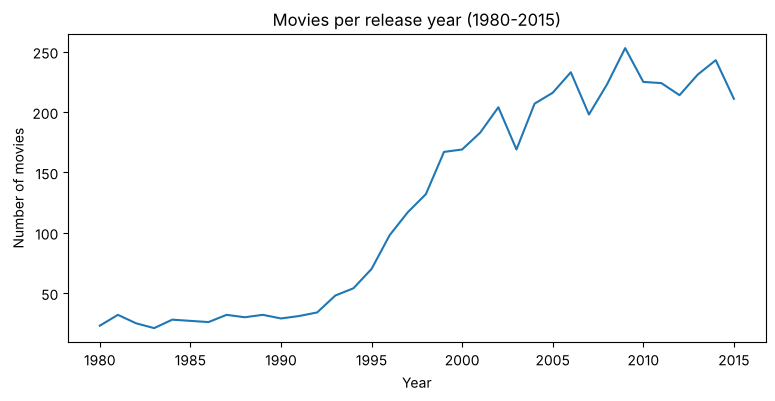

In [16]:
movies_per_year = year_df[year_df["release_year"].between(1980, 2015)].groupby("release_year").size()
print(movies_per_year.idxmax(), movies_per_year.max())
print("Average per year 1980s:", movies_per_year.loc[1980:1989].mean())
print("Average per year 2000s:", movies_per_year.loc[2000:2009].mean())

movies_per_year.plot(kind="line", figsize=(9, 4))
plt.title("Movies per release year (1980-2015)")
plt.xlabel("Year")
plt.ylabel("Number of movies")
plt.show()

**Insight:** the number of movies per year grew sharply from the 1990s. The average was about **27.6 movies per year in the 1980s** and **205.5 per year in the 2000s**. The peak year is **2009 with 253 movies**.

### Insight 2: Average IMDb score by decade

        count      mean
decade                 
1960.0     71  7.395775
1970.0    109  7.105505
1980.0    276  6.619928
1990.0    780  6.517949
2000.0   2055  6.351679
2010.0   1446  6.248963


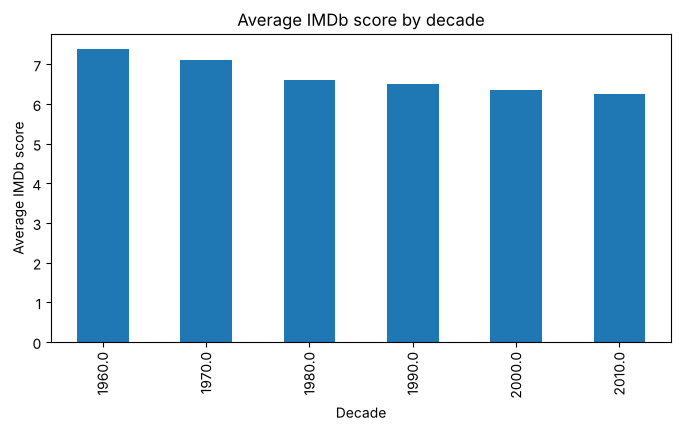

In [17]:
year_df["decade"] = (year_df["release_year"] // 10) * 10
by_decade = year_df.groupby("decade")["imdb_score"].agg(["count", "mean"])
by_decade = by_decade[by_decade["count"] >= 30]
print(by_decade)

by_decade["mean"].plot(kind="bar", figsize=(8, 4))
plt.title("Average IMDb score by decade")
plt.xlabel("Decade")
plt.ylabel("Average IMDb score")
plt.show()

**Insight:** the average IMDb score goes down with every decade, from **7.40 in the 1960s to 6.25 in the 2010s**. Newer decades have many more movies, so the average is pulled down.

### Insight 3: Most common genres and their average rating

primary_genre
Comedy         1313
Action         1113
Drama           944
Adventure       439
Crime           340
Biography       250
Horror          221
Documentary      84
Animation        61
Fantasy          48
Name: count, dtype: int64


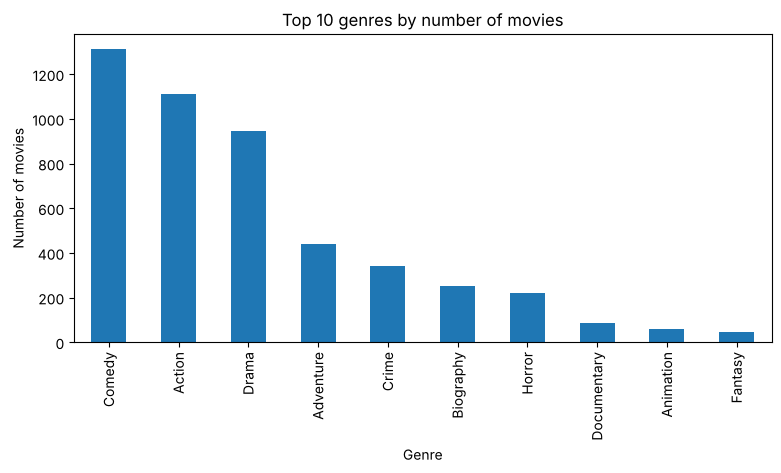

primary_genre
Horror         5.623982
Comedy         6.194136
Action         6.231626
Fantasy        6.381250
Adventure      6.530068
Animation      6.631148
Drama          6.767161
Crime          6.902941
Biography      7.157600
Documentary    7.167857
Name: imdb_score, dtype: float64


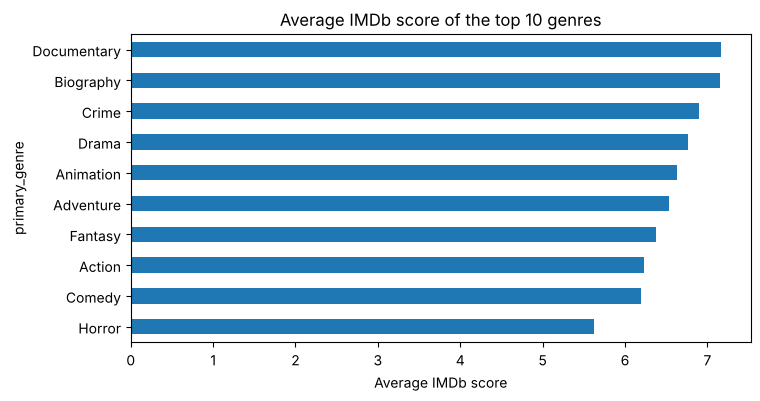

In [18]:
top_genres = df["primary_genre"].value_counts().head(10)
print(top_genres)

top_genres.plot(kind="bar", figsize=(9, 4))
plt.title("Top 10 genres by number of movies")
plt.xlabel("Genre")
plt.ylabel("Number of movies")
plt.show()

genre_score = df[df["primary_genre"].isin(top_genres.index)].groupby("primary_genre")["imdb_score"].mean().sort_values()
print(genre_score)

genre_score.plot(kind="barh", figsize=(8, 4))
plt.title("Average IMDb score of the top 10 genres")
plt.xlabel("Average IMDb score")
plt.show()

**Insight:** **Comedy (1,313), Action (1,113) and Drama (944)** are the most common genres, but the best rated are **Documentary (7.17), Biography (7.16) and Crime (6.90)**. **Horror has the lowest average score (5.62)**.

### Insight 4: Country-wise average IMDb score (countries with 40+ movies)

           count      mean
country                   
Canada       124  6.154032
Germany       94  6.315957
USA         3710  6.364987
Australia     53  6.522642
France       154  6.678571
UK           434  6.800230


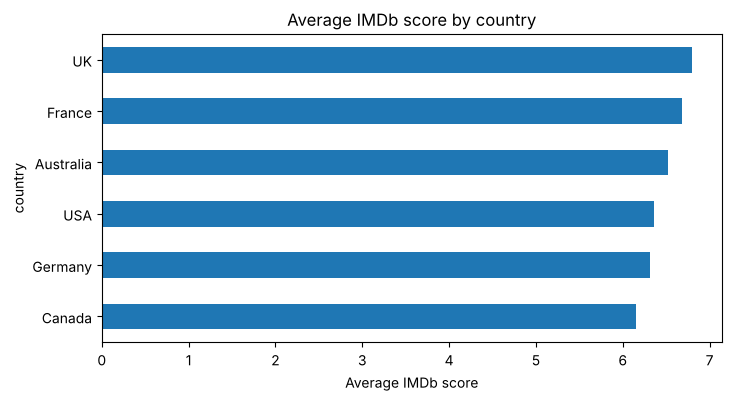

In [19]:
country = df[df["country"] != "Unknown"].groupby("country")["imdb_score"].agg(["count", "mean"])
country = country[country["count"] >= 40].sort_values("mean")
print(country)

country["mean"].plot(kind="barh", figsize=(8, 4))
plt.title("Average IMDb score by country")
plt.xlabel("Average IMDb score")
plt.show()

**Insight:** among countries with 40+ movies, the **UK (6.80) and France (6.68)** have the highest average scores. The USA (6.36) is close to the overall average, and Canada is the lowest (6.15).

### Insight 5: Average profit by genre (USA movies)

               count       mean
primary_genre                  
Documentary       32   8.719982
Drama            498  10.711163
Crime            200  11.154719
Action           729  15.395788
Comedy           862  17.645412
Biography        135  17.646079
Horror           128  22.495260
Fantasy           29  24.841053
Adventure        287  29.205126
Animation         37  36.655245


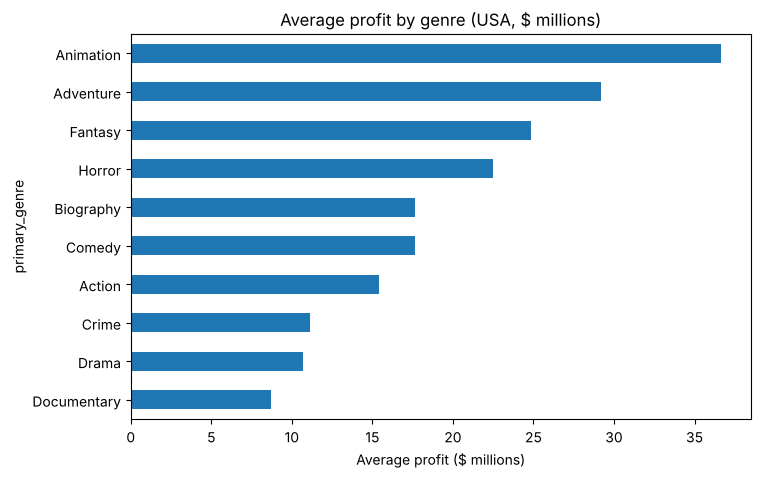

In [20]:
genre_profit = money_df.groupby("primary_genre")["profit"].agg(["count", "mean"])
genre_profit = genre_profit[genre_profit["count"] >= 25].sort_values("mean")
genre_profit["mean"] = genre_profit["mean"] / 1000000     # in millions
print(genre_profit)

genre_profit["mean"].plot(kind="barh", figsize=(8, 5))
plt.title("Average profit by genre (USA, $ millions)")
plt.xlabel("Average profit ($ millions)")
plt.show()

**Insight:** **Animation (about $36.7M) and Adventure (about $29.2M)** earn the highest average profit. Documentary (about $8.7M) and Drama (about $10.7M) earn the least.

### Insight 6: Does a bigger budget mean more revenue?

Correlation between budget and gross: 0.64
Percentage of movies that made a profit: 56.9


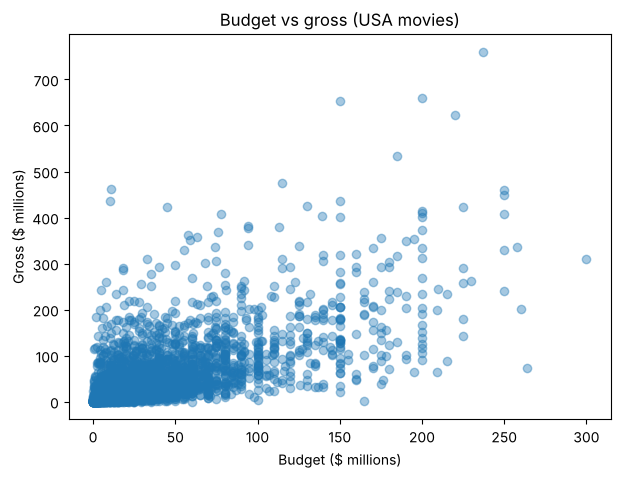

In [21]:
print("Correlation between budget and gross:", round(money_df["budget"].corr(money_df["gross"]), 2))
print("Percentage of movies that made a profit:", round((money_df["profit"] > 0).mean() * 100, 1))

plt.figure(figsize=(7, 5))
plt.scatter(money_df["budget"] / 1000000, money_df["gross"] / 1000000, alpha=0.4)
plt.title("Budget vs gross (USA movies)")
plt.xlabel("Budget ($ millions)")
plt.ylabel("Gross ($ millions)")
plt.show()

**Insight:** budget and gross have a moderate positive correlation (**0.64**), so bigger budgets generally earn more. But only **56.9%** of the USA movies made a profit, so a big budget does not guarantee success.

### Insight 7: Average gross by content rating (USA movies)

                count       mean
content_rating                  
G                  71  98.380290
PG                457  81.011579
PG-13            1076  71.639355
R                1293  36.394553


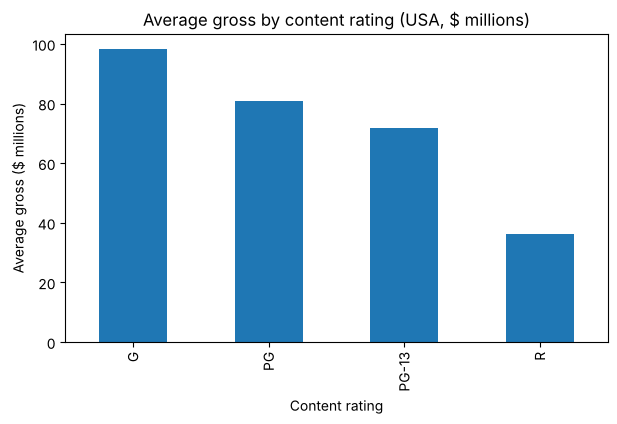

In [22]:
ratings = ["G", "PG", "PG-13", "R"]
rating_gross = money_df[money_df["content_rating"].isin(ratings)].groupby("content_rating")["gross"].agg(["count", "mean"])
rating_gross["mean"] = rating_gross["mean"] / 1000000
print(rating_gross)

rating_gross["mean"].plot(kind="bar", figsize=(7, 4))
plt.title("Average gross by content rating (USA, $ millions)")
plt.xlabel("Content rating")
plt.ylabel("Average gross ($ millions)")
plt.show()

**Insight:** **G-rated movies have the highest average gross (about $98.4M)** and **R-rated movies the lowest (about $36.4M)**. Family movies reach a bigger audience.

### Insight 8: Top 10 most profitable movies (USA)

                                    movie_title  profit_millions
0                                        Avatar       523.505847
29                               Jurassic World       502.177271
26                                      Titanic       458.672302
2973         Star Wars: Episode IV - A New Hope       449.935665
3028                 E.T. the Extra-Terrestrial       424.449459
17                                 The Avengers       403.279547
503                               The Lion King       377.783777
237   Star Wars: Episode I - The Phantom Menace       359.544677
66                              The Dark Knight       348.316061
433                            The Hunger Games       329.999255


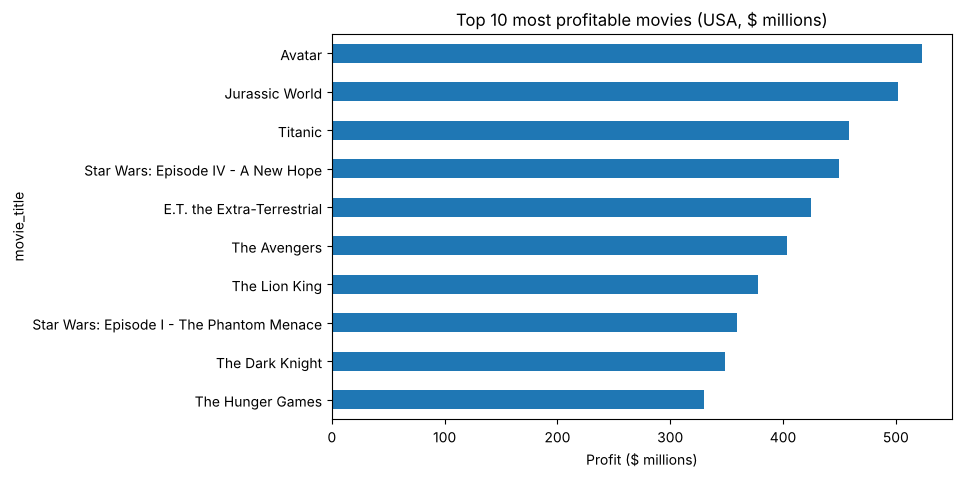

In [23]:
top_profit = money_df.sort_values("profit", ascending=False).head(10)
top_profit["profit_millions"] = top_profit["profit"] / 1000000
print(top_profit[["movie_title", "profit_millions"]])

top_profit.set_index("movie_title")["profit_millions"].sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 most profitable movies (USA, $ millions)")
plt.xlabel("Profit ($ millions)")
plt.show()

**Insight:** **Avatar (about $524M profit), Jurassic World ($502M) and Titanic ($459M)** are the three most profitable movies in the dataset.

### Insight 9: Top 10 directors by average IMDb score (at least 6 movies)

                       count      mean
director_name                         
Christopher Nolan          8  8.425000
Quentin Tarantino          8  8.200000
Stanley Kubrick            6  8.050000
James Cameron              7  7.914286
Peter Jackson              9  7.888889
Alejandro G. Iñárritu      6  7.783333
David Fincher             10  7.750000
Martin Scorsese           20  7.660000
Wes Anderson               7  7.628571
Paul Greengrass            7  7.585714


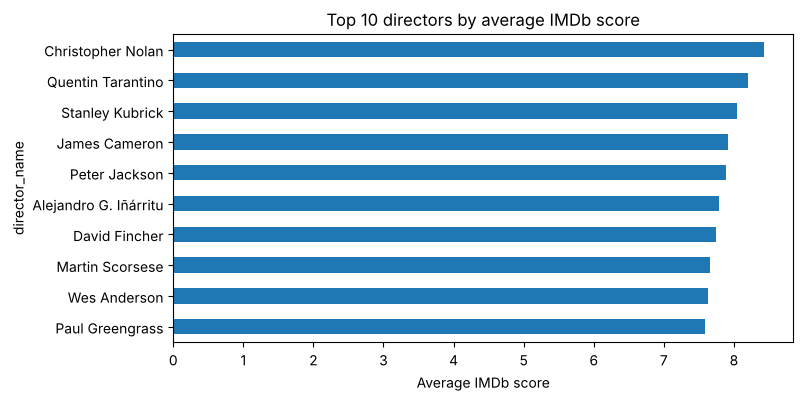

In [24]:
directors = df[df["director_name"] != "Unknown"].groupby("director_name")["imdb_score"].agg(["count", "mean"])
top_directors = directors[directors["count"] >= 6].sort_values("mean", ascending=False).head(10)
print(top_directors)

top_directors["mean"].sort_values().plot(kind="barh", figsize=(8, 4))
plt.title("Top 10 directors by average IMDb score")
plt.xlabel("Average IMDb score")
plt.show()

**Insight:** **Christopher Nolan (8.43), Quentin Tarantino (8.20) and Stanley Kubrick (8.05)** have the highest average IMDb scores among directors with at least 6 movies.

### Insight 10: Do longer movies get better ratings?

               count      mean
runtime_group                 
<90 min          941  6.115940
90-105          1743  6.128399
105-120         1193  6.602598
120-150          839  6.965435
>150 min         199  7.439196
Correlation between duration and score: 0.26


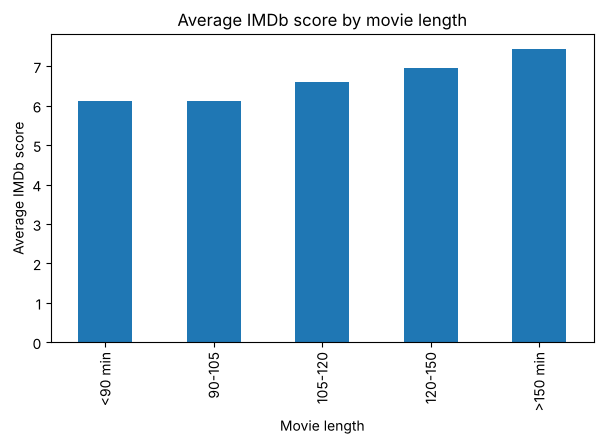

In [25]:
df["runtime_group"] = pd.cut(df["duration_min"], bins=[0, 90, 105, 120, 150, 400],
                             labels=["<90 min", "90-105", "105-120", "120-150", ">150 min"])
runtime = df.groupby("runtime_group")["imdb_score"].agg(["count", "mean"])
print(runtime)
print("Correlation between duration and score:", round(df["duration_min"].corr(df["imdb_score"]), 2))

runtime["mean"].plot(kind="bar", figsize=(7, 4))
plt.title("Average IMDb score by movie length")
plt.xlabel("Movie length")
plt.ylabel("Average IMDb score")
plt.show()

**Insight:** longer movies are rated higher. The average score rises from **6.12 for movies under 90 minutes to 7.44 for movies over 150 minutes** (correlation 0.26).

## Conclusion
* Cleaned and transformed the data: dropped 8 columns, renamed columns, added `primary_genre`, `num_genres` and `score_category`.
* Found **2,093 null values** and handled them: numeric columns with **mean imputation**, text columns with `"Unknown"`.
* Main findings: movie production grew fast after 1990; average ratings fall in newer decades; Comedy, Action and Drama are the most common genres while Documentary and Biography score best; Animation and Adventure are the most profitable; G-rated movies earn the most; longer movies score higher.